In [1]:

from google.colab import drive
import os

# Connect Google Drive
drive.mount('/content/drive')

# Main project directory
PROJECT = "/content/drive/MyDrive/AML_Assignment_4"

# Create project structure
folders = [
    "data",
    "notebooks",
    "src",
    "results",
    "results/plots",
    "results/metrics",
    "results/checkpoints",
    "results/tables",
    "app"
]

for folder in folders:
    os.makedirs(os.path.join(PROJECT, folder), exist_ok=True)

print("Project structure created successfully!")

print("\nProject location:", PROJECT)

for folder in folders:
    print("📁", folder)


Mounted at /content/drive
Project structure created successfully!

Project location: /content/drive/MyDrive/AML_Assignment_4
📁 data
📁 notebooks
📁 src
📁 results
📁 results/plots
📁 results/metrics
📁 results/checkpoints
📁 results/tables
📁 app


In [2]:

import os
import zipfile
import urllib.request
from pathlib import Path

DATA_DIR = os.path.join(PROJECT, "data")

# Official UCI dataset download
URL = "https://archive.ics.uci.edu/static/public/240/human+activity+recognition+using+smartphones.zip"

ZIP_PATH = os.path.join(DATA_DIR, "har_dataset.zip")

# Download only if not already downloaded
if not os.path.exists(ZIP_PATH):
    print("Downloading UCI dataset...")
    urllib.request.urlretrieve(URL, ZIP_PATH)
    print("Download completed!")
else:
    print("Dataset archive already exists.")

# Extract the downloaded archive
extract_dir = os.path.join(DATA_DIR, "extracted")
os.makedirs(extract_dir, exist_ok=True)

with zipfile.ZipFile(ZIP_PATH, "r") as z:
    z.extractall(extract_dir)

# Extract any nested ZIP files
while True:
    nested_zips = list(Path(extract_dir).rglob("*.zip"))
    if not nested_zips:
        break

    for nested in nested_zips:
        print("Extracting:", nested.name)
        with zipfile.ZipFile(nested, "r") as z:
            z.extractall(nested.parent)
        nested.unlink()

# Locate actual dataset root
matches = list(Path(extract_dir).rglob("Inertial Signals"))

if not matches:
    raise FileNotFoundError("Could not locate UCI HAR Inertial Signals folder.")

dataset_root = matches[0].parent.parent

print("\nDATASET DOWNLOADED SUCCESSFULLY!")
print("Dataset location:", dataset_root)
print("Train folder:", (dataset_root / "train").exists())
print("Test folder:", (dataset_root / "test").exists())


Download completed!
Extracting: UCI HAR Dataset.zip

DATASET DOWNLOADED SUCCESSFULLY!
Dataset location: /content/drive/MyDrive/AML_Assignment_4/data/extracted/__MACOSX/UCI HAR Dataset
Train folder: True
Test folder: True


In [3]:

from pathlib import Path
import json

EXTRACT_DIR = Path(PROJECT) / "data" / "extracted"

# Find the real dataset, excluding macOS metadata
candidates = [
    p.parent.parent
    for p in EXTRACT_DIR.rglob("Inertial Signals")
    if "__MACOSX" not in p.parts
]

DATASET_ROOT = None

for root in candidates:
    required = [
        root / "train" / "Inertial Signals" / "body_acc_x_train.txt",
        root / "test" / "Inertial Signals" / "body_acc_x_test.txt",
        root / "train" / "y_train.txt",
        root / "test" / "y_test.txt"
    ]

    if all(f.exists() for f in required):
        DATASET_ROOT = root
        break

if DATASET_ROOT is None:
    raise FileNotFoundError("Actual UCI dataset not found!")

# Save dataset location for future sessions
config = {
    "project": str(PROJECT),
    "dataset_root": str(DATASET_ROOT)
}

with open(os.path.join(PROJECT, "config.json"), "w") as f:
    json.dump(config, f, indent=4)

print("Correct dataset selected!")
print("Dataset root:", DATASET_ROOT)
print("Train folder:", (DATASET_ROOT / "train").exists())
print("Test folder:", (DATASET_ROOT / "test").exists())
print("Configuration saved!")


Correct dataset selected!
Dataset root: /content/drive/MyDrive/AML_Assignment_4/data/extracted/UCI HAR Dataset
Train folder: True
Test folder: True
Configuration saved!


In [4]:

import numpy as np
import json
from pathlib import Path
from collections import Counter

# Sensor channel order from assignment
CHANNELS = [
    "body_acc_x", "body_acc_y", "body_acc_z",
    "body_gyro_x", "body_gyro_y", "body_gyro_z",
    "total_acc_x", "total_acc_y", "total_acc_z"
]

def load_raw(data_root):
    data_root = Path(data_root)
    output = {}

    for split in ["train", "test"]:
        signal_dir = data_root / split / "Inertial Signals"

        X = np.stack([
            np.loadtxt(
                signal_dir / f"{channel}_{split}.txt",
                dtype=np.float32
            )
            for channel in CHANNELS
        ], axis=-1)

        y = np.loadtxt(
            data_root / split / f"y_{split}.txt",
            dtype=int
        )

        subject = np.loadtxt(
            data_root / split / f"subject_{split}.txt",
            dtype=int
        )

        output[split] = {
            "X": X,
            "y": y,
            "subject": subject
        }

    names = [
        line.split()[1]
        for line in (data_root / "activity_labels.txt")
        .read_text().splitlines()
        if line.strip()
    ]

    output["activity_names"] = names
    return output


# Load dataset
raw = load_raw(DATASET_ROOT)

# Display shapes
print("=" * 50)
print("DATASET SHAPES")
print("=" * 50)

for split in ["train", "test"]:
    print(f"\n{split.upper()}")
    print("Signals:", raw[split]["X"].shape)
    print("Labels:", raw[split]["y"].shape)
    print("Subjects:", raw[split]["subject"].shape)
    print("Unique volunteers:",
          sorted(np.unique(raw[split]["subject"]).tolist()))

# Activity distribution
print("\n" + "=" * 50)
print("ACTIVITY DISTRIBUTION")
print("=" * 50)

for split in ["train", "test"]:
    print(f"\n{split.upper()}")

    for label, name in enumerate(raw["activity_names"], start=1):
        count = np.sum(raw[split]["y"] == label)
        print(f"{label}. {name:<25} {count}")

# Save inspection results
summary = {
    "train_shape": list(raw["train"]["X"].shape),
    "test_shape": list(raw["test"]["X"].shape),
    "activity_names": raw["activity_names"],
    "train_subjects": sorted(
        np.unique(raw["train"]["subject"]).tolist()
    ),
    "test_subjects": sorted(
        np.unique(raw["test"]["subject"]).tolist()
    )
}

output_path = Path(PROJECT) / "results" / "metrics"
output_path.mkdir(parents=True, exist_ok=True)

with open(output_path / "dataset_inspection.json", "w") as f:
    json.dump(summary, f, indent=4)

print("\nInspection results saved to Google Drive!")


DATASET SHAPES

TRAIN
Signals: (7352, 128, 9)
Labels: (7352,)
Subjects: (7352,)
Unique volunteers: [1, 3, 5, 6, 7, 8, 11, 14, 15, 16, 17, 19, 21, 22, 23, 25, 26, 27, 28, 29, 30]

TEST
Signals: (2947, 128, 9)
Labels: (2947,)
Subjects: (2947,)
Unique volunteers: [2, 4, 9, 10, 12, 13, 18, 20, 24]

ACTIVITY DISTRIBUTION

TRAIN
1. WALKING                   1226
2. WALKING_UPSTAIRS          1073
3. WALKING_DOWNSTAIRS        986
4. SITTING                   1286
5. STANDING                  1374
6. LAYING                    1407

TEST
1. WALKING                   496
2. WALKING_UPSTAIRS          471
3. WALKING_DOWNSTAIRS        420
4. SITTING                   491
5. STANDING                  532
6. LAYING                    537

Inspection results saved to Google Drive!


In [5]:

# Convert labels from 1-6 to 0-5
y_train = raw["train"]["y"] - 1
y_test = raw["test"]["y"] - 1

# Verify conversion
print("Training labels:", np.unique(y_train))
print("Testing labels:", np.unique(y_test))

# Verify class counts
print("\nACTIVITY COUNTS AFTER CONVERSION")

for i, name in enumerate(raw["activity_names"]):
    train_count = np.sum(y_train == i)
    test_count = np.sum(y_test == i)

    print(f"{i}: {name:<25} Train: {train_count} | Test: {test_count}")

# Save label information
label_info = {
    "original_labels": "1-6",
    "converted_labels": "0-5",
    "activity_mapping": {
        str(i): name for i, name in enumerate(raw["activity_names"])
    }
}

with open(os.path.join(PROJECT, "results", "metrics",
                       "label_mapping.json"), "w") as f:
    json.dump(label_info, f, indent=4)

print("\nLabel conversion verified!")
print("Label mapping saved to Google Drive.")


Training labels: [0 1 2 3 4 5]
Testing labels: [0 1 2 3 4 5]

ACTIVITY COUNTS AFTER CONVERSION
0: WALKING                   Train: 1226 | Test: 496
1: WALKING_UPSTAIRS          Train: 1073 | Test: 471
2: WALKING_DOWNSTAIRS        Train: 986 | Test: 420
3: SITTING                   Train: 1286 | Test: 491
4: STANDING                  Train: 1374 | Test: 532
5: LAYING                    Train: 1407 | Test: 537

Label conversion verified!
Label mapping saved to Google Drive.


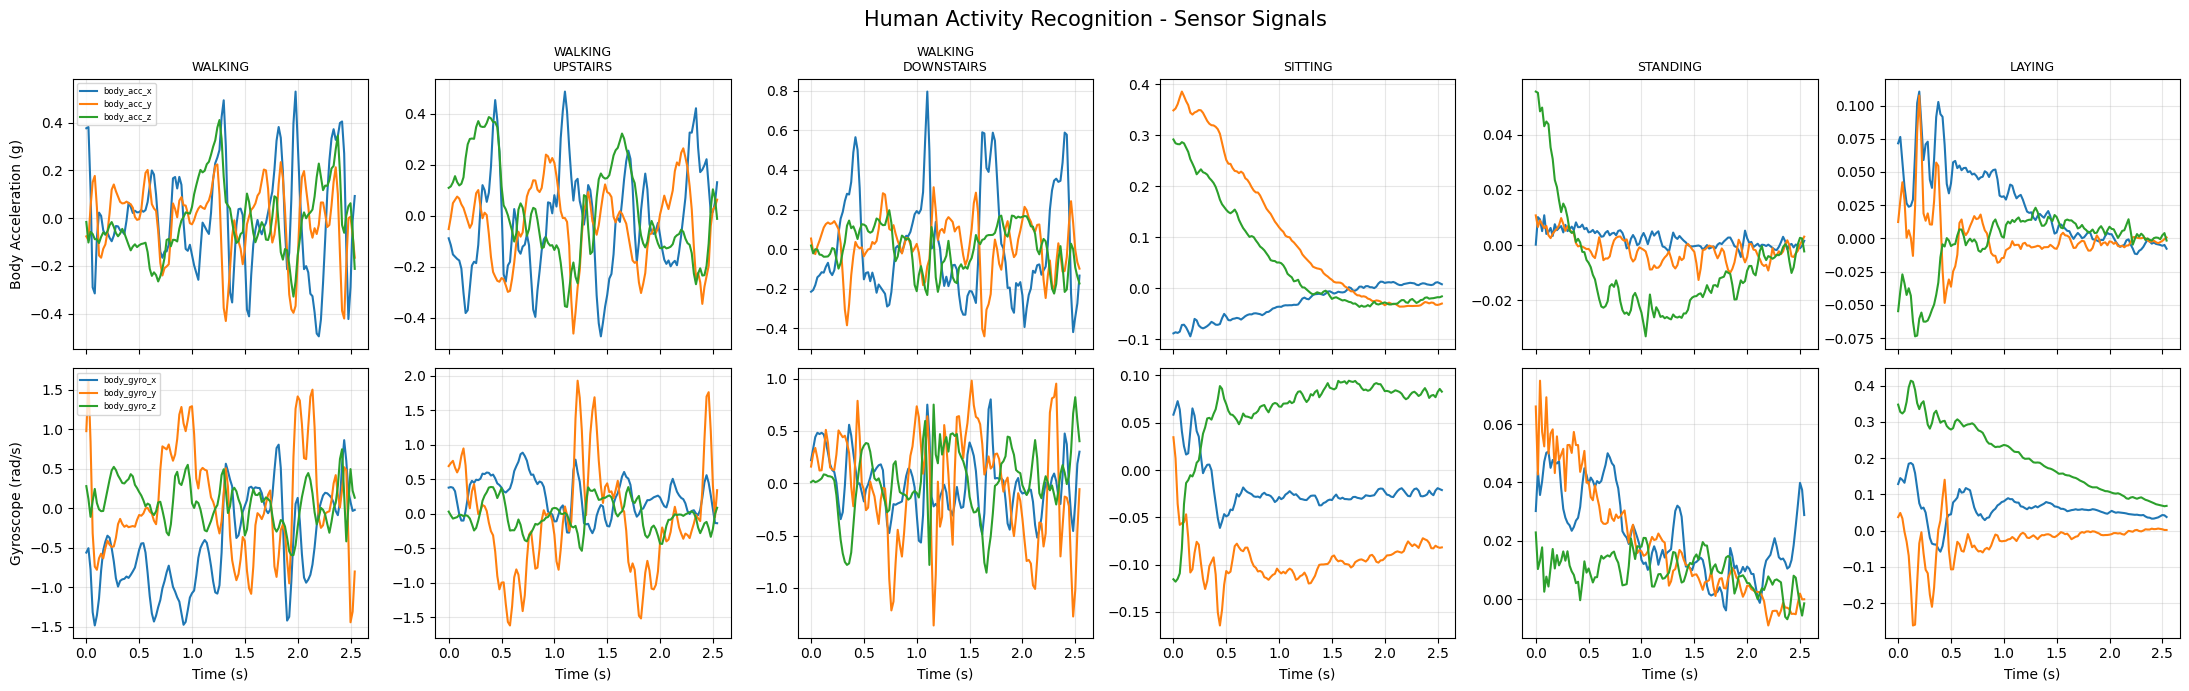

Figure saved: /content/drive/MyDrive/AML_Assignment_4/results/plots/example_windows.png


In [6]:

import matplotlib.pyplot as plt

FS = 50
t = np.arange(128) / FS

fig, axes = plt.subplots(
    2, 6,
    figsize=(22, 7),
    sharex=True
)

for k, name in enumerate(raw["activity_names"]):

    # Find first window of each activity
    idx = np.flatnonzero(raw["train"]["y"] == k + 1)[0]

    X = raw["train"]["X"][idx]

    # Body acceleration
    for c in range(3):
        axes[0, k].plot(t, X[:, c], label=CHANNELS[c])

    # Gyroscope
    for c in range(3):
        axes[1, k].plot(t, X[:, 3+c], label=CHANNELS[3+c])

    axes[0, k].set_title(name.replace("_", "\n"), fontsize=9)
    axes[0, k].grid(alpha=0.3)
    axes[1, k].grid(alpha=0.3)

    axes[1, k].set_xlabel("Time (s)")

axes[0, 0].set_ylabel("Body Acceleration (g)")
axes[1, 0].set_ylabel("Gyroscope (rad/s)")

axes[0, 0].legend(fontsize=6)
axes[1, 0].legend(fontsize=6)

fig.suptitle("Human Activity Recognition - Sensor Signals", fontsize=15)
plt.tight_layout()

# Save figure
PLOT_PATH = os.path.join(
    PROJECT, "results", "plots", "example_windows.png"
)

plt.savefig(PLOT_PATH, dpi=150, bbox_inches="tight")
plt.show()

print("Figure saved:", PLOT_PATH)


In [7]:

# Required validation volunteers
VAL_SUBJECTS = [3, 15, 25, 30]

# Original training data
X_all = raw["train"]["X"]
y_all = y_train
subjects = raw["train"]["subject"]

# Create subject-based masks
is_val = np.isin(subjects, VAL_SUBJECTS)
is_train = ~is_val

# Split data
X_train = X_all[is_train]
y_train_final = y_all[is_train]
train_subjects = subjects[is_train]

X_val = X_all[is_val]
y_val = y_all[is_val]
val_subjects = subjects[is_val]

# Original test data (untouched)
X_test = raw["test"]["X"]
y_test_final = y_test
test_subjects = raw["test"]["subject"]

# Display results
print("=" * 50)
print("SUBJECT-BASED DATA SPLIT")
print("=" * 50)

print("\nTRAINING")
print("Windows:", X_train.shape[0])
print("Subjects:", sorted(np.unique(train_subjects)))

print("\nVALIDATION")
print("Windows:", X_val.shape[0])
print("Subjects:", sorted(np.unique(val_subjects)))

print("\nTESTING")
print("Windows:", X_test.shape[0])
print("Subjects:", sorted(np.unique(test_subjects)))

# Verify no overlap
assert set(train_subjects).isdisjoint(set(val_subjects))
assert set(train_subjects).isdisjoint(set(test_subjects))
assert set(val_subjects).isdisjoint(set(test_subjects))

assert sorted(np.unique(val_subjects).tolist()) == VAL_SUBJECTS

print("\nAll subject separation checks passed!")

# Save split statistics
split_info = {
    "training_windows": len(X_train),
    "validation_windows": len(X_val),
    "testing_windows": len(X_test),
    "training_subjects": sorted(np.unique(train_subjects).tolist()),
    "validation_subjects": sorted(np.unique(val_subjects).tolist()),
    "testing_subjects": sorted(np.unique(test_subjects).tolist())
}

with open(os.path.join(PROJECT, "results", "metrics",
                       "split_summary.json"), "w") as f:
    json.dump(split_info, f, indent=4)

print("\nSplit information saved to Google Drive!")


SUBJECT-BASED DATA SPLIT

TRAINING
Windows: 5891
Subjects: [np.int64(1), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(11), np.int64(14), np.int64(16), np.int64(17), np.int64(19), np.int64(21), np.int64(22), np.int64(23), np.int64(26), np.int64(27), np.int64(28), np.int64(29)]

VALIDATION
Windows: 1461
Subjects: [np.int64(3), np.int64(15), np.int64(25), np.int64(30)]

TESTING
Windows: 2947
Subjects: [np.int64(2), np.int64(4), np.int64(9), np.int64(10), np.int64(12), np.int64(13), np.int64(18), np.int64(20), np.int64(24)]

All subject separation checks passed!

Split information saved to Google Drive!


In [8]:

# Calculate statistics using training data only
channel_mean = X_train.mean(axis=(0, 1))
channel_std = X_train.std(axis=(0, 1))

# Prevent division by zero
channel_std[channel_std == 0] = 1.0

# Standardize all three datasets
X_train_scaled = (
    X_train - channel_mean
) / channel_std

X_val_scaled = (
    X_val - channel_mean
) / channel_std

X_test_scaled = (
    X_test - channel_mean
) / channel_std

# Verify results
print("TRAINING STANDARDIZATION")
print("Mean:", np.round(X_train_scaled.mean(axis=(0, 1)), 4))
print("Std:", np.round(X_train_scaled.std(axis=(0, 1)), 4))

print("\nDATASET SHAPES")
print("Training:", X_train_scaled.shape)
print("Validation:", X_val_scaled.shape)
print("Testing:", X_test_scaled.shape)

# Save normalization statistics
stats = {
    "channels": CHANNELS,
    "mean": channel_mean.tolist(),
    "std": channel_std.tolist()
}

with open(os.path.join(PROJECT, "results", "metrics",
                       "normalization_stats.json"), "w") as f:
    json.dump(stats, f, indent=4)

print("\nNormalization statistics saved!")


TRAINING STANDARDIZATION
Mean: [ 0.     -0.      0.      0.     -0.      0.      0.0001 -0.      0.    ]
Std: [1.     1.     1.     1.     1.     1.     1.     0.9999 1.    ]

DATASET SHAPES
Training: (5891, 128, 9)
Validation: (1461, 128, 9)
Testing: (2947, 128, 9)

Normalization statistics saved!


In [9]:

import torch

# Convert signals to float32 tensors
X_train_tensor = torch.tensor(X_train_scaled, dtype=torch.float32)
X_val_tensor = torch.tensor(X_val_scaled, dtype=torch.float32)
X_test_tensor = torch.tensor(X_test_scaled, dtype=torch.float32)

# Convert labels to long tensors
y_train_tensor = torch.tensor(y_train_final, dtype=torch.long)
y_val_tensor = torch.tensor(y_val, dtype=torch.long)
y_test_tensor = torch.tensor(y_test_final, dtype=torch.long)

# Verify shapes and data types
datasets = {
    "Training": (X_train_tensor, y_train_tensor),
    "Validation": (X_val_tensor, y_val_tensor),
    "Testing": (X_test_tensor, y_test_tensor)
}

for name, (X, y) in datasets.items():
    print(f"\n{name}")
    print("Signal shape:", X.shape)
    print("Label shape:", y.shape)
    print("Signal dtype:", X.dtype)
    print("Label dtype:", y.dtype)

# Save prepared tensors
TENSOR_PATH = os.path.join(
    PROJECT, "data", "prepared_tensors.pt"
)

torch.save({
    "X_train": X_train_tensor,
    "y_train": y_train_tensor,
    "X_val": X_val_tensor,
    "y_val": y_val_tensor,
    "X_test": X_test_tensor,
    "y_test": y_test_tensor,
    "activity_names": raw["activity_names"],
    "channels": CHANNELS
}, TENSOR_PATH)

# Final checks
assert X_train_tensor.shape[1:] == (128, 9)
assert X_val_tensor.shape[1:] == (128, 9)
assert X_test_tensor.shape[1:] == (128, 9)

assert X_train_tensor.dtype == torch.float32
assert y_train_tensor.dtype == torch.long

print("\nAll tensor checks passed!")
print("Prepared tensors saved:", TENSOR_PATH)



Training
Signal shape: torch.Size([5891, 128, 9])
Label shape: torch.Size([5891])
Signal dtype: torch.float32
Label dtype: torch.int64

Validation
Signal shape: torch.Size([1461, 128, 9])
Label shape: torch.Size([1461])
Signal dtype: torch.float32
Label dtype: torch.int64

Testing
Signal shape: torch.Size([2947, 128, 9])
Label shape: torch.Size([2947])
Signal dtype: torch.float32
Label dtype: torch.int64

All tensor checks passed!
Prepared tensors saved: /content/drive/MyDrive/AML_Assignment_4/data/prepared_tensors.pt


Task 2.1: Implement RNN Cell

In [10]:

import torch
import torch.nn as nn
import math
import os

INPUT_SIZE = 9
HIDDEN_SIZE = 64

class RNNCell(nn.Module):

    def __init__(self, input_size, hidden_size):
        super().__init__()

        self.input_size = input_size
        self.hidden_size = hidden_size

        self.W = nn.Parameter(
            torch.empty(hidden_size, input_size)
        )

        self.U = nn.Parameter(
            torch.empty(hidden_size, hidden_size)
        )

        self.b = nn.Parameter(
            torch.empty(hidden_size)
        )

        self.reset_parameters()

    def reset_parameters(self):
        bound = 1 / math.sqrt(self.hidden_size)

        nn.init.uniform_(self.W, -bound, bound)
        nn.init.uniform_(self.U, -bound, bound)
        nn.init.uniform_(self.b, -bound, bound)

    def forward(self, x, h_prev):

        h = torch.tanh(
            x @ self.W.T +
            h_prev @ self.U.T +
            self.b
        )

        return h


# Test RNN Cell
rnn_cell = RNNCell(INPUT_SIZE, HIDDEN_SIZE)

batch_size = 64

x = torch.randn(batch_size, INPUT_SIZE)
h_prev = torch.zeros(batch_size, HIDDEN_SIZE)

h_new = rnn_cell(x, h_prev)

print("RNN CELL TEST")
print("Input shape:", x.shape)
print("Previous hidden state:", h_prev.shape)
print("New hidden state:", h_new.shape)

print("\nTrainable parameters:",
      sum(p.numel() for p in rnn_cell.parameters()))

assert h_new.shape == (64, 64)

print("\nRNN Cell implemented successfully!")


RNN CELL TEST
Input shape: torch.Size([64, 9])
Previous hidden state: torch.Size([64, 64])
New hidden state: torch.Size([64, 64])

Trainable parameters: 4736

RNN Cell implemented successfully!


In [11]:

class LSTMCell(nn.Module):

    def __init__(self, input_size, hidden_size):
        super().__init__()

        self.input_size = input_size
        self.hidden_size = hidden_size

        self.W = nn.Parameter(
            torch.empty(4 * hidden_size, input_size)
        )

        self.U = nn.Parameter(
            torch.empty(4 * hidden_size, hidden_size)
        )

        self.b = nn.Parameter(
            torch.empty(4 * hidden_size)
        )

        self.reset_parameters()

    def reset_parameters(self):
        bound = 1 / math.sqrt(self.hidden_size)

        nn.init.uniform_(self.W, -bound, bound)
        nn.init.uniform_(self.U, -bound, bound)
        nn.init.uniform_(self.b, -bound, bound)

    def forward(self, x, h_prev, c_prev):

        gates = (
            x @ self.W.T +
            h_prev @ self.U.T +
            self.b
        )

        i, f, g, o = gates.chunk(4, dim=1)

        i = torch.sigmoid(i)
        f = torch.sigmoid(f)
        g = torch.tanh(g)
        o = torch.sigmoid(o)

        c = f * c_prev + i * g

        h = o * torch.tanh(c)

        return h, c


# Test LSTM Cell
lstm_cell = LSTMCell(INPUT_SIZE, HIDDEN_SIZE)

batch_size = 64

x = torch.randn(batch_size, INPUT_SIZE)
h_prev = torch.zeros(batch_size, HIDDEN_SIZE)
c_prev = torch.zeros(batch_size, HIDDEN_SIZE)

h_new, c_new = lstm_cell(x, h_prev, c_prev)

print("LSTM CELL TEST")
print("Input shape:", x.shape)
print("Hidden state:", h_new.shape)
print("Cell state:", c_new.shape)

print("\nTrainable parameters:",
      sum(p.numel() for p in lstm_cell.parameters()))

assert h_new.shape == (64, 64)
assert c_new.shape == (64, 64)

print("\nLSTM Cell implemented successfully!")


LSTM CELL TEST
Input shape: torch.Size([64, 9])
Hidden state: torch.Size([64, 64])
Cell state: torch.Size([64, 64])

Trainable parameters: 18944

LSTM Cell implemented successfully!


In [12]:

class LSTM(nn.Module):

    def __init__(self, input_size, hidden_size):
        super().__init__()

        self.hidden_size = hidden_size
        self.cell = LSTMCell(input_size, hidden_size)

    def forward(self, x):

        batch_size, seq_length, _ = x.shape

        h = x.new_zeros(batch_size, self.hidden_size)
        c = x.new_zeros(batch_size, self.hidden_size)

        outputs = []

        for t in range(seq_length):

            x_t = x[:, t, :]

            h, c = self.cell(x_t, h, c)

            outputs.append(h)

        outputs = torch.stack(outputs, dim=1)

        return outputs


# Test LSTM Layer
lstm_layer = LSTM(INPUT_SIZE, HIDDEN_SIZE)

test_input = torch.randn(64, 128, 9)

lstm_output = lstm_layer(test_input)

print("LSTM LAYER TEST")
print("Input shape:", test_input.shape)
print("Output shape:", lstm_output.shape)

print("\nTrainable parameters:",
      sum(p.numel() for p in lstm_layer.parameters()))

assert lstm_output.shape == (64, 128, 64)

print("\nLSTM Layer implemented successfully!")


LSTM LAYER TEST
Input shape: torch.Size([64, 128, 9])
Output shape: torch.Size([64, 128, 64])

Trainable parameters: 18944

LSTM Layer implemented successfully!


In [13]:

class BiLSTM(nn.Module):

    def __init__(self, input_size, hidden_size):
        super().__init__()

        self.forward_lstm = LSTM(input_size, hidden_size)
        self.backward_lstm = LSTM(input_size, hidden_size)

    def forward(self, x):

        # Forward direction
        forward_output = self.forward_lstm(x)

        # Reverse input sequence
        reversed_x = torch.flip(x, dims=[1])

        # Backward direction
        backward_output = self.backward_lstm(reversed_x)

        # Restore original time order
        backward_output = torch.flip(
            backward_output, dims=[1]
        )

        # Concatenate both directions
        output = torch.cat(
            [forward_output, backward_output],
            dim=2
        )

        return output


# Test BiLSTM
bilstm = BiLSTM(INPUT_SIZE, HIDDEN_SIZE)

test_input = torch.randn(64, 128, 9)

bilstm_output = bilstm(test_input)

print("BILSTM TEST")
print("Input shape:", test_input.shape)
print("Output shape:", bilstm_output.shape)

print("\nTrainable parameters:",
      sum(p.numel() for p in bilstm.parameters()))

assert bilstm_output.shape == (64, 128, 128)

print("\nBiLSTM implemented successfully!")


BILSTM TEST
Input shape: torch.Size([64, 128, 9])
Output shape: torch.Size([64, 128, 128])

Trainable parameters: 37888

BiLSTM implemented successfully!


In [14]:

class Attention(nn.Module):

    def __init__(self, hidden_size):
        super().__init__()

        self.Wa = nn.Parameter(
            torch.empty(hidden_size, 2 * hidden_size)
        )

        self.ba = nn.Parameter(
            torch.empty(hidden_size)
        )

        self.v = nn.Parameter(
            torch.empty(hidden_size)
        )

        self.reset_parameters()

    def reset_parameters(self):
        bound = 1 / math.sqrt(HIDDEN_SIZE)

        nn.init.uniform_(self.Wa, -bound, bound)
        nn.init.uniform_(self.ba, -bound, bound)
        nn.init.uniform_(self.v, -bound, bound)

    def forward(self, H):

        # Calculate attention scores
        scores = torch.tanh(
            H @ self.Wa.T + self.ba
        ) @ self.v

        # Calculate attention weights
        alpha = torch.softmax(scores, dim=1)

        # Calculate context vector
        context = torch.sum(
            alpha.unsqueeze(-1) * H,
            dim=1
        )

        return context, alpha


# Test Attention
attention = Attention(HIDDEN_SIZE)

test_input = torch.randn(64, 128, 128)

context, alpha = attention(test_input)

print("ATTENTION TEST")
print("Input shape:", test_input.shape)
print("Context vector:", context.shape)
print("Attention weights:", alpha.shape)

print("\nAttention sum:", alpha[0].sum().item())
print("Minimum weight:", alpha.min().item())
print("Maximum weight:", alpha.max().item())

print("\nTrainable parameters:",
      sum(p.numel() for p in attention.parameters()))

assert context.shape == (64, 128)
assert alpha.shape == (64, 128)
assert torch.allclose(
    alpha.sum(dim=1),
    torch.ones(64),
    atol=1e-6
)

print("\nAttention implemented successfully!")


ATTENTION TEST
Input shape: torch.Size([64, 128, 128])
Context vector: torch.Size([64, 128])
Attention weights: torch.Size([64, 128])

Attention sum: 1.0000001192092896
Minimum weight: 0.0022209954913705587
Maximum weight: 0.030723612755537033

Trainable parameters: 8320

Attention implemented successfully!


In [15]:

class HARNet(nn.Module):

    def __init__(self, input_size=9, hidden_size=64,
                 num_classes=6):
        super().__init__()

        self.bilstm = BiLSTM(input_size, hidden_size)

        self.attention = Attention(hidden_size)

        self.fc = nn.Linear(
            2 * hidden_size,
            num_classes
        )

    def forward(self, x):

        # Bidirectional LSTM
        H = self.bilstm(x)

        # Attention
        context, alpha = self.attention(H)

        # Classification
        logits = self.fc(context)

        return logits, alpha


# Required initialization seed
torch.manual_seed(0)

# Create complete model
model = HARNet(
    input_size=9,
    hidden_size=64,
    num_classes=6
)

# Count trainable parameters
total_params = sum(
    p.numel() for p in model.parameters()
    if p.requires_grad
)

print("HARNET MODEL TEST")
print("=" * 40)

# Test forward pass
test_input = torch.randn(64, 128, 9)

logits, alpha = model(test_input)

print("Input shape:", test_input.shape)
print("Logits shape:", logits.shape)
print("Attention shape:", alpha.shape)

print("\nTrainable parameters:", total_params)

# Parameter calculation
print("\nPARAMETER CALCULATION")
print("Forward LSTM: 18944")
print("Backward LSTM: 18944")
print("Attention: 8320")
print("Linear layer:", 128 * 6 + 6)
print("Total:", total_params)

# Initial loss check
criterion = nn.CrossEntropyLoss()
initial_loss = criterion(
    logits,
    torch.randint(0, 6, (64,))
)

print("\nInitial loss:", initial_loss.item())
print("Expected initial loss approximately:", math.log(6))

assert logits.shape == (64, 6)
assert alpha.shape == (64, 128)
assert total_params == 46982

print("\nHARNet implemented successfully!")


HARNET MODEL TEST
Input shape: torch.Size([64, 128, 9])
Logits shape: torch.Size([64, 6])
Attention shape: torch.Size([64, 128])

Trainable parameters: 46982

PARAMETER CALCULATION
Forward LSTM: 18944
Backward LSTM: 18944
Attention: 8320
Linear layer: 774
Total: 46982

Initial loss: 1.7973086833953857
Expected initial loss approximately: 1.791759469228055

HARNet implemented successfully!


In [1]:

import torch

print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    device = torch.device("cuda")
    print("GPU:", torch.cuda.get_device_name(0))
    print("GPU memory:", round(
        torch.cuda.get_device_properties(0).total_memory / 1024**3, 2
    ), "GB")
else:
    device = torch.device("cpu")
    print("Using CPU")

print("\nSelected device:", device)


CUDA available: True
GPU: Tesla T4
GPU memory: 14.56 GB

Selected device: cuda


In [4]:

from google.colab import drive
import os
import json
import torch
import numpy as np
import math
import torch.nn as nn

# Reconnect Google Drive
drive.mount('/content/drive')

# Restore project path
PROJECT = "/content/drive/MyDrive/AML_Assignment_4"

# Restore dataset path
DATASET_ROOT = os.path.join(
    PROJECT, "data", "extracted", "UCI HAR Dataset"
)

# Check important files
print("\nPROJECT RESTORATION")
print("Project exists:", os.path.exists(PROJECT))
print("Dataset exists:", os.path.exists(DATASET_ROOT))
print("Prepared tensors exist:", os.path.exists(
    os.path.join(PROJECT, "data", "prepared_tensors.pt")
))

# Recreate config if missing
config = {
    "project": PROJECT,
    "dataset_root": DATASET_ROOT
}

with open(os.path.join(PROJECT, "config.json"), "w") as f:
    json.dump(config, f, indent=4)

print("\nConfiguration restored successfully!")
print("GPU available:", torch.cuda.is_available())


Mounted at /content/drive

PROJECT RESTORATION
Project exists: True
Dataset exists: True
Prepared tensors exist: True

Configuration restored successfully!
GPU available: True


In [5]:

from torch.utils.data import TensorDataset, DataLoader

# Load prepared tensors
TENSOR_PATH = os.path.join(
    PROJECT, "data", "prepared_tensors.pt"
)

saved = torch.load(
    TENSOR_PATH,
    map_location="cpu",
    weights_only=False
)

X_train_tensor = saved["X_train"]
y_train_tensor = saved["y_train"]

X_val_tensor = saved["X_val"]
y_val_tensor = saved["y_val"]

X_test_tensor = saved["X_test"]
y_test_tensor = saved["y_test"]

# Configure GPU
device = torch.device("cuda")

# Create datasets
train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
val_dataset = TensorDataset(X_val_tensor, y_val_tensor)
test_dataset = TensorDataset(X_test_tensor, y_test_tensor)

# Create DataLoaders
BATCH_SIZE = 64

train_loader = DataLoader(
    train_dataset, batch_size=64,
    shuffle=True, pin_memory=True
)

val_loader = DataLoader(
    val_dataset, batch_size=64,
    shuffle=False, pin_memory=True
)

test_loader = DataLoader(
    test_dataset, batch_size=64,
    shuffle=False, pin_memory=True
)

print("DATA RESTORED SUCCESSFULLY")
print("GPU:", torch.cuda.get_device_name(0))

print("\nTraining batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Testing batches:", len(test_loader))

print("\nBatch shape:", next(iter(train_loader))[0].shape)
print("Training samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))
print("Testing samples:", len(test_dataset))


DATA RESTORED SUCCESSFULLY
GPU: Tesla T4

Training batches: 93
Validation batches: 23
Testing batches: 47

Batch shape: torch.Size([64, 128, 9])
Training samples: 5891
Validation samples: 1461
Testing samples: 2947


In [6]:

import torch
import torch.nn as nn
import math

# RNN CELL
class RNNCell(nn.Module):
    def __init__(self, input_size, hidden_size):
        super().__init__()
        self.hidden_size = hidden_size
        self.W = nn.Parameter(torch.empty(hidden_size, input_size))
        self.U = nn.Parameter(torch.empty(hidden_size, hidden_size))
        self.b = nn.Parameter(torch.empty(hidden_size))
        self.reset_parameters()

    def reset_parameters(self):
        bound = 1 / math.sqrt(self.hidden_size)
        nn.init.uniform_(self.W, -bound, bound)
        nn.init.uniform_(self.U, -bound, bound)
        nn.init.uniform_(self.b, -bound, bound)

    def forward(self, x, h_prev):
        return torch.tanh(
            x @ self.W.T + h_prev @ self.U.T + self.b
        )


# LSTM CELL
class LSTMCell(nn.Module):
    def __init__(self, input_size, hidden_size):
        super().__init__()
        self.hidden_size = hidden_size
        self.W = nn.Parameter(torch.empty(4 * hidden_size, input_size))
        self.U = nn.Parameter(torch.empty(4 * hidden_size, hidden_size))
        self.b = nn.Parameter(torch.empty(4 * hidden_size))
        self.reset_parameters()

    def reset_parameters(self):
        bound = 1 / math.sqrt(self.hidden_size)
        nn.init.uniform_(self.W, -bound, bound)
        nn.init.uniform_(self.U, -bound, bound)
        nn.init.uniform_(self.b, -bound, bound)

    def forward(self, x, h_prev, c_prev):
        gates = x @ self.W.T + h_prev @ self.U.T + self.b
        i, f, g, o = gates.chunk(4, dim=1)

        i = torch.sigmoid(i)
        f = torch.sigmoid(f)
        g = torch.tanh(g)
        o = torch.sigmoid(o)

        c = f * c_prev + i * g
        h = o * torch.tanh(c)

        return h, c


# LSTM LAYER
class LSTM(nn.Module):
    def __init__(self, input_size, hidden_size):
        super().__init__()
        self.hidden_size = hidden_size
        self.cell = LSTMCell(input_size, hidden_size)

    def forward(self, x):
        batch_size, seq_length, _ = x.shape

        h = x.new_zeros(batch_size, self.hidden_size)
        c = x.new_zeros(batch_size, self.hidden_size)

        outputs = []

        for t in range(seq_length):
            h, c = self.cell(x[:, t, :], h, c)
            outputs.append(h)

        return torch.stack(outputs, dim=1)


# BIDIRECTIONAL LSTM
class BiLSTM(nn.Module):
    def __init__(self, input_size, hidden_size):
        super().__init__()
        self.forward_lstm = LSTM(input_size, hidden_size)
        self.backward_lstm = LSTM(input_size, hidden_size)

    def forward(self, x):
        forward_output = self.forward_lstm(x)

        reversed_x = torch.flip(x, dims=[1])
        backward_output = self.backward_lstm(reversed_x)
        backward_output = torch.flip(backward_output, dims=[1])

        return torch.cat(
            [forward_output, backward_output], dim=2
        )


# ATTENTION
class Attention(nn.Module):
    def __init__(self, hidden_size):
        super().__init__()
        self.Wa = nn.Parameter(torch.empty(hidden_size, 2 * hidden_size))
        self.ba = nn.Parameter(torch.empty(hidden_size))
        self.v = nn.Parameter(torch.empty(hidden_size))
        self.reset_parameters()

    def reset_parameters(self):
        bound = 1 / math.sqrt(64)
        nn.init.uniform_(self.Wa, -bound, bound)
        nn.init.uniform_(self.ba, -bound, bound)
        nn.init.uniform_(self.v, -bound, bound)

    def forward(self, H):
        scores = torch.tanh(H @ self.Wa.T + self.ba) @ self.v
        alpha = torch.softmax(scores, dim=1)
        context = torch.sum(alpha.unsqueeze(-1) * H, dim=1)
        return context, alpha


# COMPLETE HARNET
class HARNet(nn.Module):
    def __init__(self, input_size=9, hidden_size=64, num_classes=6):
        super().__init__()
        self.bilstm = BiLSTM(input_size, hidden_size)
        self.attention = Attention(hidden_size)
        self.fc = nn.Linear(2 * hidden_size, num_classes)

    def forward(self, x):
        H = self.bilstm(x)
        context, alpha = self.attention(H)
        logits = self.fc(context)
        return logits, alpha


# Initialize model
torch.manual_seed(0)

model = HARNet().to(device)

total_params = sum(
    p.numel() for p in model.parameters()
    if p.requires_grad
)

print("HARNet restored successfully!")
print("Device:", device)
print("Trainable parameters:", total_params)

assert total_params == 46982

# Forward pass verification
test_input = torch.randn(4, 128, 9, device=device)
logits, alpha = model(test_input)

print("Logits:", logits.shape)
print("Attention:", alpha.shape)

assert logits.shape == (4, 6)
assert alpha.shape == (4, 128)

print("\nAll architecture checks passed!")


HARNet restored successfully!
Device: cuda
Trainable parameters: 46982
Logits: torch.Size([4, 6])
Attention: torch.Size([4, 128])

All architecture checks passed!


In [7]:

import time
import csv
import copy
import matplotlib.pyplot as plt

# Training configuration
EPOCHS = 30
LEARNING_RATE = 0.001
GRAD_CLIP = 1.0

# Loss and optimizer
criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=LEARNING_RATE
)

# Output directories
RESULTS_DIR = os.path.join(PROJECT, "results")
CHECKPOINT_DIR = os.path.join(RESULTS_DIR, "checkpoints")
METRICS_DIR = os.path.join(RESULTS_DIR, "metrics")
PLOTS_DIR = os.path.join(RESULTS_DIR, "plots")

os.makedirs(CHECKPOINT_DIR, exist_ok=True)
os.makedirs(METRICS_DIR, exist_ok=True)
os.makedirs(PLOTS_DIR, exist_ok=True)

# Calculate initial training loss before updates
model.eval()

with torch.no_grad():
    X, y = next(iter(train_loader))
    X = X.to(device)
    y = y.to(device)

    initial_logits, _ = model(X)
    initial_loss = criterion(initial_logits, y).item()

print("TRAINING CONFIGURATION")
print("=" * 40)
print("Device:", device)
print("Optimizer: Adam")
print("Learning rate:", LEARNING_RATE)
print("Batch size:", BATCH_SIZE)
print("Epochs:", EPOCHS)
print("Gradient clipping:", GRAD_CLIP)
print("Initial training batch loss:", initial_loss)

print("\nTraining configuration ready!")


TRAINING CONFIGURATION
Device: cuda
Optimizer: Adam
Learning rate: 0.001
Batch size: 64
Epochs: 30
Gradient clipping: 1.0
Initial training batch loss: 1.7961403131484985

Training configuration ready!


In [8]:

# Training history
history = {
    "epoch": [],
    "train_loss": [],
    "val_loss": [],
    "val_accuracy": []
}

best_val_loss = float("inf")
best_epoch = 0
best_model_state = None

training_start = time.time()

for epoch in range(EPOCHS):

    # =========================
    # TRAINING
    # =========================
    model.train()

    train_loss_total = 0.0
    train_samples = 0

    for X, y in train_loader:

        X = X.to(device, non_blocking=True)
        y = y.to(device, non_blocking=True)

        optimizer.zero_grad()

        logits, alpha = model(X)
        loss = criterion(logits, y)

        loss.backward()

        # Required gradient clipping
        torch.nn.utils.clip_grad_norm_(
            model.parameters(), GRAD_CLIP
        )

        optimizer.step()

        train_loss_total += loss.item() * y.size(0)
        train_samples += y.size(0)

    train_loss = train_loss_total / train_samples

    # =========================
    # VALIDATION
    # =========================
    model.eval()

    val_loss_total = 0.0
    correct = 0
    val_samples = 0

    with torch.no_grad():

        for X, y in val_loader:

            X = X.to(device, non_blocking=True)
            y = y.to(device, non_blocking=True)

            logits, alpha = model(X)
            loss = criterion(logits, y)

            predictions = torch.argmax(logits, dim=1)

            val_loss_total += loss.item() * y.size(0)
            correct += (predictions == y).sum().item()
            val_samples += y.size(0)

    val_loss = val_loss_total / val_samples
    val_accuracy = 100 * correct / val_samples

    # Record history
    history["epoch"].append(epoch + 1)
    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["val_accuracy"].append(val_accuracy)

    # Save best model
    if val_loss < best_val_loss:

        best_val_loss = val_loss
        best_epoch = epoch + 1

        best_model_state = copy.deepcopy(
            model.state_dict()
        )

        torch.save({
            "epoch": best_epoch,
            "model_state_dict": best_model_state,
            "optimizer_state_dict": optimizer.state_dict(),
            "best_val_loss": best_val_loss
        }, os.path.join(
            CHECKPOINT_DIR, "best_harnet.pth"
        ))

    print(
        f"Epoch [{epoch+1:02d}/{EPOCHS}] "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Accuracy: {val_accuracy:.2f}%"
        + ("  *BEST*" if epoch + 1 == best_epoch else "")
    )

# Restore best validation checkpoint
model.load_state_dict(best_model_state)

training_time = time.time() - training_start

# Save history CSV
csv_path = os.path.join(
    METRICS_DIR, "training_history.csv"
)

with open(csv_path, "w", newline="") as f:
    writer = csv.writer(f)
    writer.writerow([
        "epoch", "train_loss",
        "val_loss", "val_accuracy"
    ])

    for i in range(EPOCHS):
        writer.writerow([
            history["epoch"][i],
            history["train_loss"][i],
            history["val_loss"][i],
            history["val_accuracy"][i]
        ])

# Save training summary
summary = {
    "best_epoch": best_epoch,
    "best_validation_loss": best_val_loss,
    "training_time_seconds": training_time,
    "initial_training_loss": initial_loss,
    "final_training_loss": history["train_loss"][-1],
    "final_validation_loss": history["val_loss"][-1],
    "final_validation_accuracy": history["val_accuracy"][-1]
}

with open(os.path.join(
    METRICS_DIR, "training_summary.json"
), "w") as f:
    json.dump(summary, f, indent=4)

print("\n" + "=" * 50)
print("TRAINING COMPLETED")
print("=" * 50)
print("Best epoch:", best_epoch)
print("Best validation loss:", round(best_val_loss, 5))
print("Training time:", round(training_time / 60, 2), "minutes")
print("Best model saved successfully!")
print("Training history saved successfully!")


Epoch [01/30] Train Loss: 0.9969 | Val Loss: 0.3193 | Val Accuracy: 91.65%  *BEST*
Epoch [02/30] Train Loss: 0.2010 | Val Loss: 0.1606 | Val Accuracy: 95.76%  *BEST*
Epoch [03/30] Train Loss: 0.1517 | Val Loss: 0.1872 | Val Accuracy: 94.05%
Epoch [04/30] Train Loss: 0.1388 | Val Loss: 0.1723 | Val Accuracy: 93.57%
Epoch [05/30] Train Loss: 0.1306 | Val Loss: 0.1367 | Val Accuracy: 95.35%  *BEST*
Epoch [06/30] Train Loss: 0.1239 | Val Loss: 0.1367 | Val Accuracy: 94.52%  *BEST*
Epoch [07/30] Train Loss: 0.1214 | Val Loss: 0.1890 | Val Accuracy: 91.51%
Epoch [08/30] Train Loss: 0.1174 | Val Loss: 0.1373 | Val Accuracy: 95.07%
Epoch [09/30] Train Loss: 0.1211 | Val Loss: 0.2229 | Val Accuracy: 93.22%
Epoch [10/30] Train Loss: 0.1152 | Val Loss: 0.1323 | Val Accuracy: 94.39%  *BEST*
Epoch [11/30] Train Loss: 0.1149 | Val Loss: 0.1866 | Val Accuracy: 93.91%
Epoch [12/30] Train Loss: 0.1110 | Val Loss: 0.1347 | Val Accuracy: 94.39%
Epoch [13/30] Train Loss: 0.1151 | Val Loss: 0.2063 | Val Ac

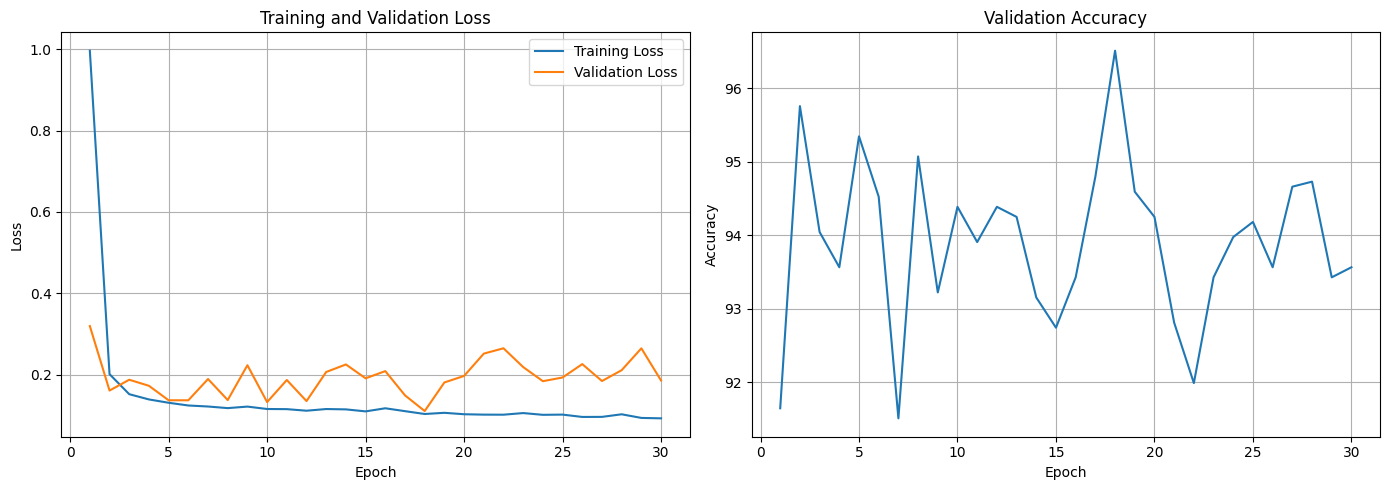

Saved: /content/drive/MyDrive/AML_Assignment_4/results/plots/training_curves.png

Best epoch: 18
Best validation loss: 0.1102001508658225
Best validation accuracy: 96.50924024640658


In [9]:
import pandas as pd
import matplotlib.pyplot as plt
import os

history_path = os.path.join(
    PROJECT, "results", "metrics", "training_history.csv"
)

history_df = pd.read_csv(history_path)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Loss curves
axes[0].plot(history_df["epoch"], history_df["train_loss"], label="Training Loss")
axes[0].plot(history_df["epoch"], history_df["val_loss"], label="Validation Loss")
axes[0].set_title("Training and Validation Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(True)

# Validation accuracy
axes[1].plot(history_df["epoch"], history_df["val_accuracy"])
axes[1].set_title("Validation Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].grid(True)

plt.tight_layout()

save_path = os.path.join(
    PROJECT, "results", "plots", "training_curves.png"
)

plt.savefig(save_path, dpi=300, bbox_inches="tight")
plt.show()

print("Saved:", save_path)
print("\nBest epoch:", history_df.loc[history_df["val_loss"].idxmin(), "epoch"])
print("Best validation loss:", history_df["val_loss"].min())
print("Best validation accuracy:", history_df["val_accuracy"].max())

TEST ACCURACY: 91.11 %

PER-CLASS ACCURACY:
Walking: 89.11%
Upstairs: 98.09%
Downstairs: 97.14%
Sitting: 79.63%
Standing: 83.65%
Laying: 100.0%

CONFUSION MATRIX:
[[442  30  24   0   0   0]
 [  6 462   1   1   1   0]
 [  1   9 408   0   2   0]
 [  0   2   0 391  98   0]
 [  0   0   0  87 445   0]
 [  0   0   0   0   0 537]]


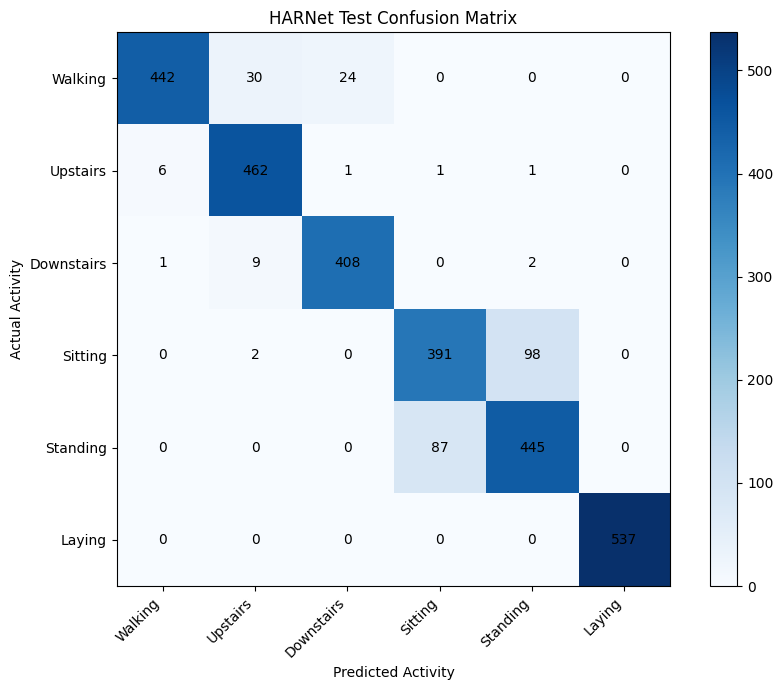


All test results saved successfully.


In [10]:
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import json
import os

# Load best saved model
checkpoint_path = os.path.join(
    PROJECT, "results", "checkpoints", "best_harnet.pth"
)

checkpoint = torch.load(
    checkpoint_path,
    map_location=device,
    weights_only=False
)

model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

all_predictions = []
all_labels = []

# Test evaluation
with torch.no_grad():
    for X, y in test_loader:
        X = X.to(device)
        logits, attention = model(X)

        predictions = torch.argmax(logits, dim=1)

        all_predictions.extend(predictions.cpu().numpy())
        all_labels.extend(y.numpy())

y_true = np.array(all_labels)
y_pred = np.array(all_predictions)

# Overall accuracy
accuracy = np.mean(y_true == y_pred) * 100

# Confusion matrix (implemented manually)
num_classes = 6
confusion = np.zeros((num_classes, num_classes), dtype=int)

for actual, predicted in zip(y_true, y_pred):
    confusion[actual, predicted] += 1

class_names = [
    "Walking", "Upstairs", "Downstairs",
    "Sitting", "Standing", "Laying"
]

# Per-class accuracy
per_class_accuracy = {}

for i, name in enumerate(class_names):
    class_acc = (
        confusion[i, i] / confusion[i].sum()
    ) * 100
    per_class_accuracy[name] = round(float(class_acc), 2)

print("TEST ACCURACY:", round(accuracy, 2), "%")
print("\nPER-CLASS ACCURACY:")

for name, score in per_class_accuracy.items():
    print(f"{name}: {score}%")

print("\nCONFUSION MATRIX:")
print(confusion)

# Save confusion matrix CSV
metrics_dir = os.path.join(PROJECT, "results", "metrics")

pd.DataFrame(
    confusion,
    index=class_names,
    columns=class_names
).to_csv(os.path.join(metrics_dir, "confusion_matrix.csv"))

# Save test metrics
test_results = {
    "test_accuracy": round(float(accuracy), 2),
    "correct_predictions": int(np.sum(y_true == y_pred)),
    "total_predictions": int(len(y_true)),
    "per_class_accuracy": per_class_accuracy,
    "confusion_matrix": confusion.tolist()
}

with open(os.path.join(metrics_dir, "test_results.json"), "w") as f:
    json.dump(test_results, f, indent=4)

# Plot confusion matrix
plt.figure(figsize=(9, 7))
plt.imshow(confusion, cmap="Blues")
plt.colorbar()

plt.xticks(range(6), class_names, rotation=45, ha="right")
plt.yticks(range(6), class_names)

plt.xlabel("Predicted Activity")
plt.ylabel("Actual Activity")
plt.title("HARNet Test Confusion Matrix")

for i in range(6):
    for j in range(6):
        plt.text(j, i, confusion[i, j],
                 ha="center", va="center")

plt.tight_layout()

plot_path = os.path.join(
    PROJECT, "results", "plots", "confusion_matrix.png"
)

plt.savefig(plot_path, dpi=300, bbox_inches="tight")
plt.show()

print("\nAll test results saved successfully.")

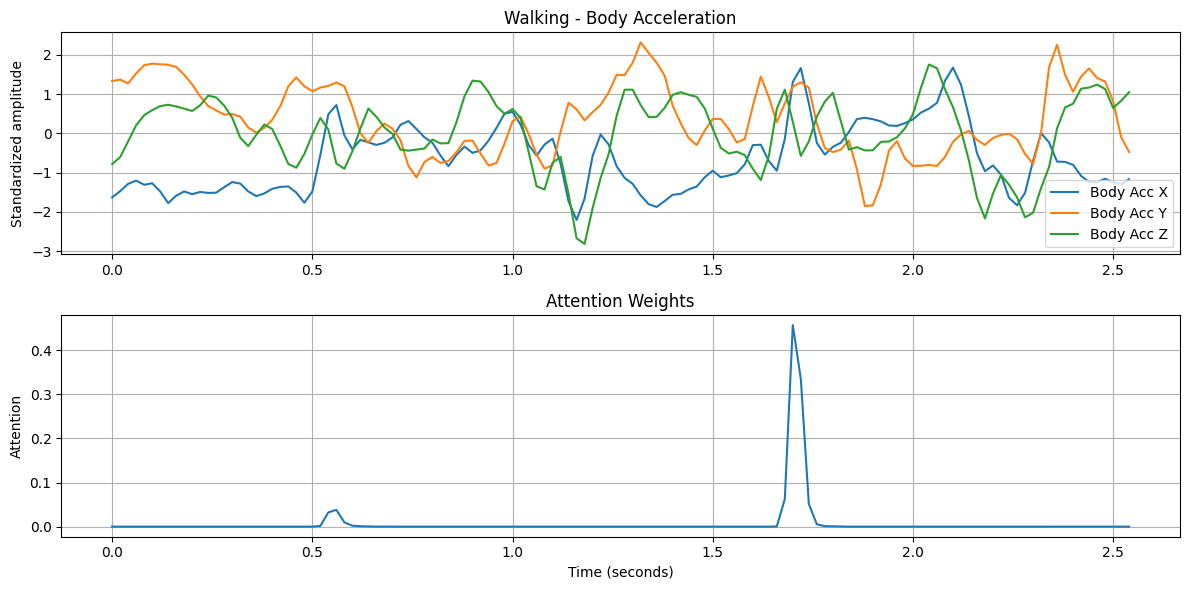

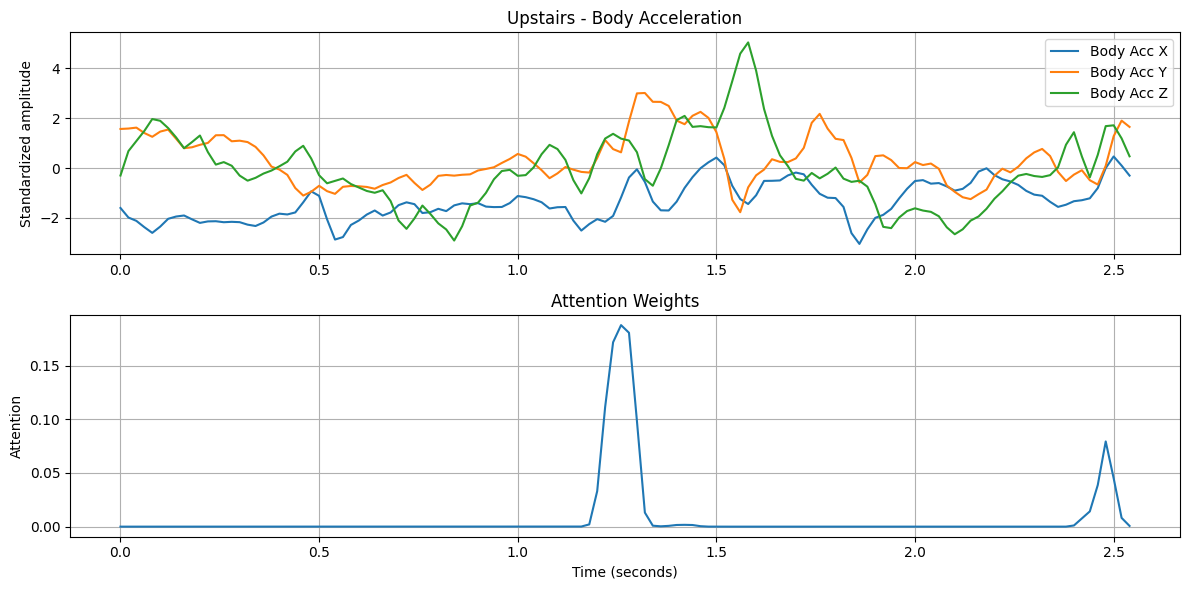

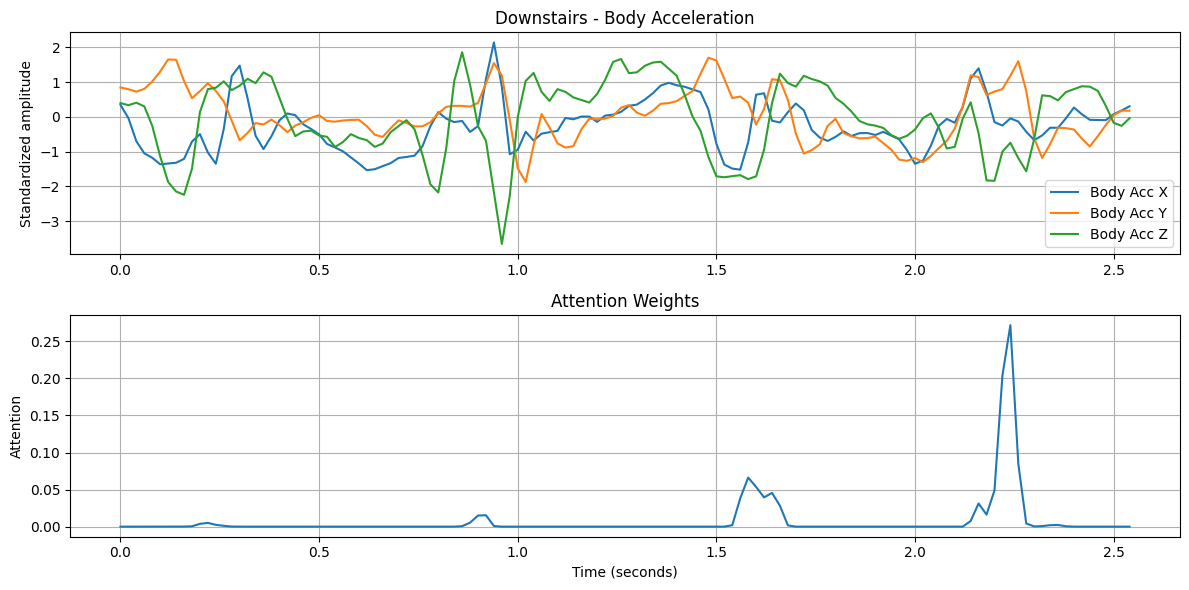

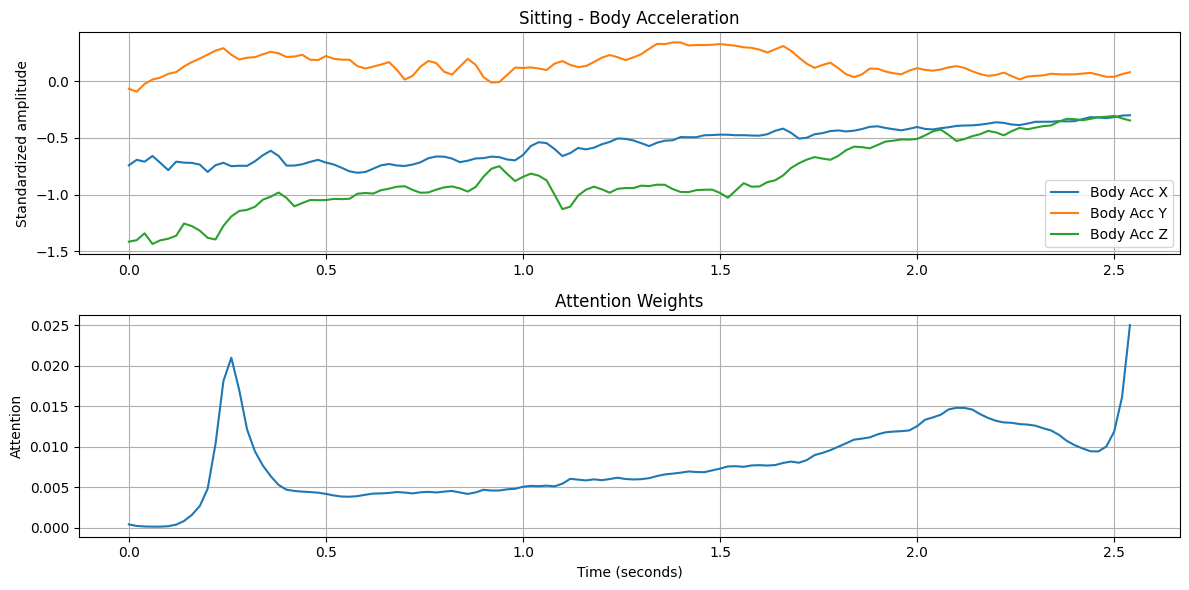

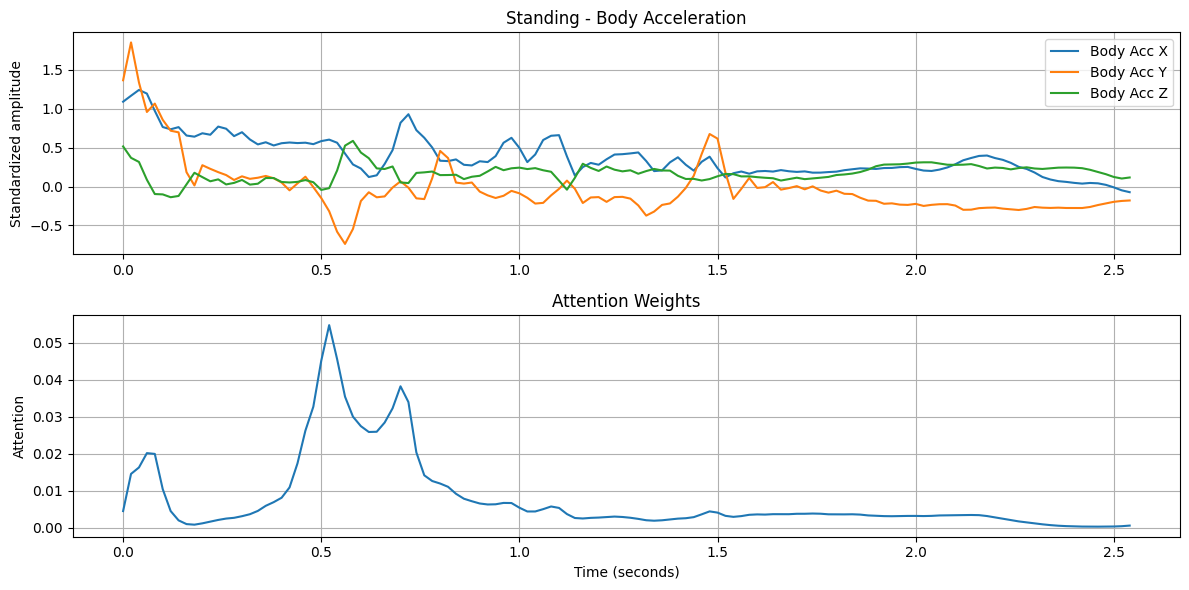

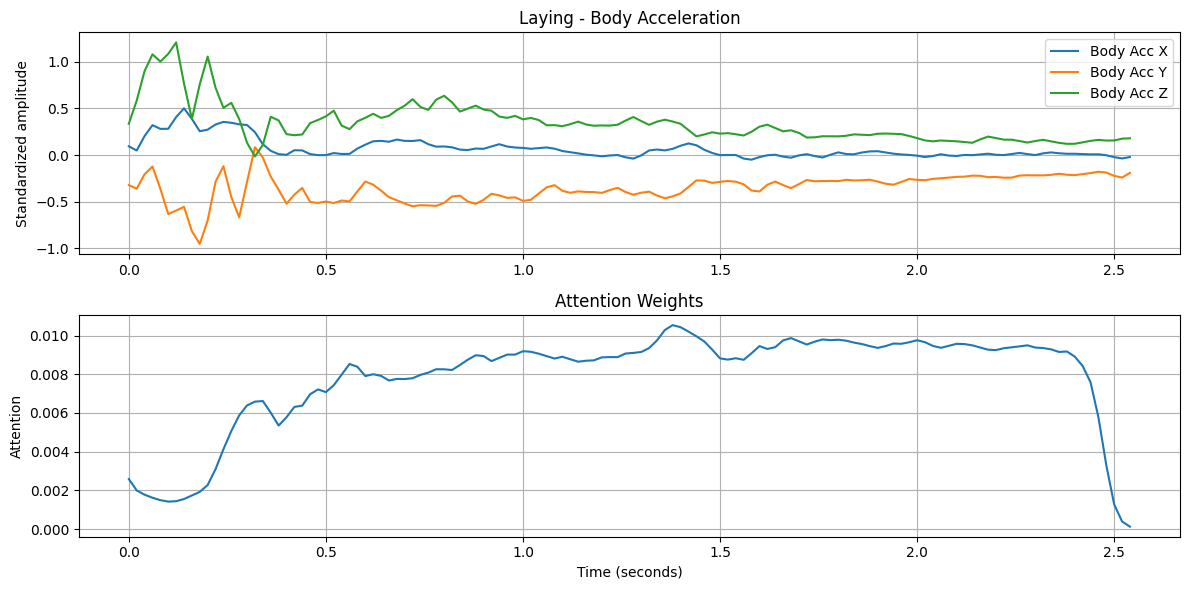

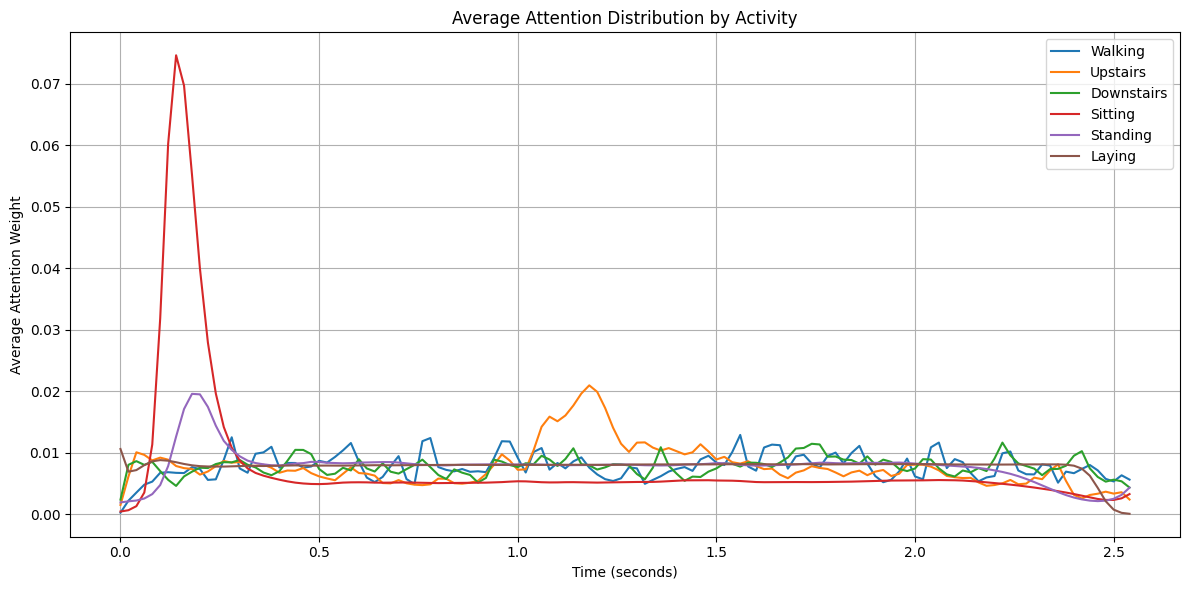

MEAN MAXIMUM ATTENTION PER ACTIVITY:
Walking: 0.326123
Upstairs: 0.225232
Downstairs: 0.2345
Sitting: 0.105216
Standing: 0.035428
Laying: 0.017623

Attention visualizations and metrics saved successfully!


In [11]:
import numpy as np
import matplotlib.pyplot as plt
import os
import json
import torch

class_names = [
    "Walking", "Upstairs", "Downstairs",
    "Sitting", "Standing", "Laying"
]

plots_dir = os.path.join(PROJECT, "results", "plots")
metrics_dir = os.path.join(PROJECT, "results", "metrics")

os.makedirs(plots_dir, exist_ok=True)
os.makedirs(metrics_dir, exist_ok=True)

# Collect attention weights and one correct example per activity
attention_by_class = {i: [] for i in range(6)}
correct_examples = {}

model.eval()

with torch.no_grad():
    for X, y in test_loader:
        X_device = X.to(device)

        logits, alpha = model(X_device)
        predictions = torch.argmax(logits, dim=1).cpu().numpy()

        X_numpy = X.numpy()
        alpha_numpy = alpha.cpu().numpy()
        labels_numpy = y.numpy()

        for i in range(len(labels_numpy)):
            actual = int(labels_numpy[i])
            predicted = int(predictions[i])

            attention_by_class[actual].append(alpha_numpy[i])

            if actual == predicted and actual not in correct_examples:
                correct_examples[actual] = {
                    "signal": X_numpy[i],
                    "attention": alpha_numpy[i]
                }

# 1. Plot one correctly classified example per activity
time_axis = np.arange(128) / 50

for class_id, name in enumerate(class_names):

    example = correct_examples[class_id]
    signal = example["signal"]
    alpha = example["attention"]

    fig, axes = plt.subplots(2, 1, figsize=(12, 6))

    # Body acceleration channels: x, y, z
    axes[0].plot(time_axis, signal[:, 3], label="Body Acc X")
    axes[0].plot(time_axis, signal[:, 4], label="Body Acc Y")
    axes[0].plot(time_axis, signal[:, 5], label="Body Acc Z")

    axes[0].set_title(f"{name} - Body Acceleration")
    axes[0].set_ylabel("Standardized amplitude")
    axes[0].legend()
    axes[0].grid(True)

    axes[1].plot(time_axis, alpha)
    axes[1].set_title("Attention Weights")
    axes[1].set_xlabel("Time (seconds)")
    axes[1].set_ylabel("Attention")
    axes[1].grid(True)

    plt.tight_layout()

    filename = f"attention_example_{name.lower()}.png"
    plt.savefig(
        os.path.join(plots_dir, filename),
        dpi=300,
        bbox_inches="tight"
    )
    plt.show()
    plt.close()

# 2. Average attention per activity
average_attention = {}

plt.figure(figsize=(12, 6))

for class_id, name in enumerate(class_names):
    weights = np.array(attention_by_class[class_id])
    avg_weights = weights.mean(axis=0)

    average_attention[name] = avg_weights.tolist()

    plt.plot(time_axis, avg_weights, label=name)

plt.title("Average Attention Distribution by Activity")
plt.xlabel("Time (seconds)")
plt.ylabel("Average Attention Weight")
plt.legend()
plt.grid(True)
plt.tight_layout()

plt.savefig(
    os.path.join(plots_dir, "average_attention_by_activity.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close()

# 3. Mean maximum attention per activity
mean_max_attention = {}

print("MEAN MAXIMUM ATTENTION PER ACTIVITY:")

for class_id, name in enumerate(class_names):
    weights = np.array(attention_by_class[class_id])
    max_per_window = weights.max(axis=1)

    mean_max_attention[name] = round(
        float(max_per_window.mean()), 6
    )

    print(f"{name}: {mean_max_attention[name]}")

# Save attention analysis
attention_results = {
    "mean_max_attention": mean_max_attention,
    "average_attention": average_attention
}

with open(
    os.path.join(metrics_dir, "attention_analysis.json"), "w"
) as f:
    json.dump(attention_results, f, indent=4)

print("\nAttention visualizations and metrics saved successfully!")

In [12]:
analysis_path = os.path.join(PROJECT, "results", "analysis.md")

analysis_text = """
# HARNet Assignment 4 — Results Analysis

## 1. Model Performance

The custom HARNet model achieved 91.11% test accuracy.

The best validation checkpoint was obtained at epoch 18.

- Best validation loss: 0.1102
- Best validation accuracy: 96.51%
- Test accuracy: 91.11%

## 2. Per-Class Performance

| Activity | Accuracy |
|---|---:|
| Walking | 89.11% |
| Upstairs | 98.09% |
| Downstairs | 97.14% |
| Sitting | 79.63% |
| Standing | 83.65% |
| Laying | 100.00% |

Laying achieved perfect classification. Sitting and standing were the most challenging activities.

## 3. Confusion Matrix Observations

The largest classification errors occurred between sitting and standing.

- 98 sitting windows were classified as standing.
- 87 standing windows were classified as sitting.

These activities have similar motion characteristics, which makes them difficult to distinguish.

## 4. Attention Analysis

Mean maximum attention weight per activity:

| Activity | Mean Maximum Attention |
|---|---:|
| Walking | 0.326123 |
| Upstairs | 0.225232 |
| Downstairs | 0.234500 |
| Sitting | 0.105216 |
| Standing | 0.035428 |
| Laying | 0.017623 |

Moving activities generally showed more concentrated attention, while standing and laying showed more distributed attention.

These values describe attention concentration, not classification accuracy.

The average attention plots and individual examples provide additional temporal information.
"""

with open(analysis_path, "w") as f:
    f.write(analysis_text)

print("Analysis saved successfully:")
print(analysis_path)

Analysis saved successfully:
/content/drive/MyDrive/AML_Assignment_4/results/analysis.md


In [13]:
analysis_path = os.path.join(PROJECT, "results", "analysis.md")

answers = """

## 5. Conceptual Analysis — Task 6

### 6.1 Why split validation data by person?

The dataset windows overlap by 50%. Random splitting could place highly similar
neighbouring windows from the same person in both training and validation sets.
This can cause data leakage and overestimate model performance. Splitting by
person evaluates generalization to unseen volunteers.

### 6.2 Which activities are confused most often?

Sitting and standing are confused most often. The confusion matrix shows
98 sitting windows predicted as standing and 87 standing windows predicted
as sitting. Their motion patterns are similar when measured using a waist-worn
phone, making them difficult to distinguish.

### 6.3 Why is LAYING recognized accurately?

The total acceleration X, Y and Z signals include gravity. When a person lies
down, the phone's orientation relative to gravity becomes distinctive and
relatively stable. This helps the model identify the laying activity.

### 6.4 Is attention more peaked for moving or still activities?

Attention is generally more concentrated for moving activities in our results.
Walking has a mean maximum attention of 0.326123, compared with 0.225232 for
upstairs and 0.234500 for downstairs. Still activities generally have lower
values, although sitting is an exception compared with standing and laying.
This suggests that informative temporal patterns may be more concentrated
during movement.

### 6.5 Why is BiLSTM allowed here?

The model receives a complete 2.56-second window, so it can process the
sequence in both forward and backward directions. This is suitable for
offline activity recognition. A bidirectional model would not be suitable
for strictly real-time prediction when future sensor samples are unavailable.

### 6.6 Why does LSTM retain information better than a plain RNN?

The LSTM cell state is updated using:

c_t = f_t * c_(t-1) + i_t * g_t

The forget gate controls how much previous information is retained, while
the input gate controls how much new information is added. This gated,
additive update helps preserve information across long sequences.

Gradient clipping limits the gradient norm to 1.0 and helps prevent
exploding gradients during training.
"""

with open(analysis_path, "a") as f:
    f.write(answers)

print("Task 6 answers appended successfully!")
print(analysis_path)

Task 6 answers appended successfully!
/content/drive/MyDrive/AML_Assignment_4/results/analysis.md


frontend

In [32]:
import torch

print("Model architecture:")
print(model)

print("\nTrainable parameters:",
      sum(p.numel() for p in model.parameters() if p.requires_grad))

print("\nCheckpoint exists:",
      __import__("os").path.exists(
          PROJECT + "/results/checkpoints/best_harnet.pth"
      ))

Model architecture:
HARNet(
  (bilstm): BiLSTM(
    (forward_lstm): LSTM(
      (cell): LSTMCell()
    )
    (backward_lstm): LSTM(
      (cell): LSTMCell()
    )
  )
  (attention): Attention()
  (fc): Linear(in_features=128, out_features=6, bias=True)
)

Trainable parameters: 46982

Checkpoint exists: True


In [33]:
for i, cell in enumerate(In):
    if any(f"class {name}" in cell for name in [
        "RNNCell", "LSTMCell", "LSTM", "BiLSTM", "Attention", "HARNet"
    ]):
        print(f"\n--- Cell {i} ---")
        print(cell[:5000])


--- Cell 6 ---
import torch
import torch.nn as nn
import math

# RNN CELL
class RNNCell(nn.Module):
    def __init__(self, input_size, hidden_size):
        super().__init__()
        self.hidden_size = hidden_size
        self.W = nn.Parameter(torch.empty(hidden_size, input_size))
        self.U = nn.Parameter(torch.empty(hidden_size, hidden_size))
        self.b = nn.Parameter(torch.empty(hidden_size))
        self.reset_parameters()

    def reset_parameters(self):
        bound = 1 / math.sqrt(self.hidden_size)
        nn.init.uniform_(self.W, -bound, bound)
        nn.init.uniform_(self.U, -bound, bound)
        nn.init.uniform_(self.b, -bound, bound)

    def forward(self, x, h_prev):
        return torch.tanh(
            x @ self.W.T + h_prev @ self.U.T + self.b
        )


# LSTM CELL
class LSTMCell(nn.Module):
    def __init__(self, input_size, hidden_size):
        super().__init__()
        self.hidden_size = hidden_size
        self.W = nn.Parameter(torch.empty(4 * hidden

In [34]:
model_code = '''import torch
import torch.nn as nn
import math

''' + "\\n".join(In[6].split("# Initialize model")[0].split("# RNN CELL")[1:])

model_code = "# RNN CELL" + model_code

src_file = os.path.join(PROJECT, "src", "model.py")

with open(src_file, "w") as f:
    f.write(model_code)

print("Saved:", src_file)
print("Size:", os.path.getsize(src_file), "bytes")

Saved: /content/drive/MyDrive/AML_Assignment_4/src/model.py
Size: 4098 bytes


In [ ]:
import gradio as gr
import matplotlib.pyplot as plt
import numpy as np
import torch

class_names = [
    "Walking", "Upstairs", "Downstairs",
    "Sitting", "Standing", "Laying"
]

model.eval()

def predict_activity(window_index):

    index = int(window_index)

    # Get selected test window
    X = X_test_tensor[index:index+1].to(device)

    with torch.no_grad():
        logits, attention = model(X)

        probabilities = torch.softmax(logits, dim=1)[0].cpu().numpy()
        predicted_class = int(torch.argmax(logits, dim=1).item())

    prediction = {
        class_names[i]: float(probabilities[i])
        for i in range(6)
    }

    # Sensor signal visualization
    signal = X_test_tensor[index].numpy()
    time_axis = np.arange(128) / 50

    fig1, axes = plt.subplots(3, 1, figsize=(12, 8))

    channels = [
        ("Body Acceleration", 0, 3),
        ("Body Gyroscope", 3, 6),
        ("Total Acceleration", 6, 9)
    ]

    for ax, (title, start, end) in zip(axes, channels):
        for channel in range(start, end):
            ax.plot(
                time_axis,
                signal[:, channel],
                label=f"Channel {channel+1}"
            )

        ax.set_title(title)
        ax.set_xlabel("Time (seconds)")
        ax.legend()
        ax.grid(True)

    fig1.tight_layout()

    # Attention visualization
    attention_weights = attention[0].cpu().numpy()

    fig2, ax = plt.subplots(figsize=(12, 3))
    ax.plot(time_axis, attention_weights)
    ax.set_title("HARNet Temporal Attention")
    ax.set_xlabel("Time (seconds)")
    ax.set_ylabel("Attention Weight")
    ax.grid(True)
    fig2.tight_layout()

    actual_label = class_names[int(y_test_tensor[index])]

    result_text = (
        f"Predicted Activity: {class_names[predicted_class]}\n"
        f"Actual Activity: {actual_label}\n"
        f"Test Window: {index}"
    )

    return result_text, prediction, fig1, fig2


with gr.Blocks(theme=gr.themes.Soft(), title="HARNet Activity Recognition") as demo:

    gr.Markdown(
        """
        # HARNet — Human Activity Recognition
        ### LSTM + BiLSTM + Temporal Attention | PyTorch
        Select a test window to recognize human activity from smartphone sensors.
        """
    )

    with gr.Row():
        window_input = gr.Slider(
            minimum=0,
            maximum=len(X_test_tensor)-1,
            value=0,
            step=1,
            label="Select Test Window"
        )

        predict_button = gr.Button(
            "Predict Activity",
            variant="primary"
        )

    result = gr.Textbox(
        label="Prediction Result",
        interactive=False
    )

    probabilities = gr.Label(
        label="Activity Probabilities",
        num_top_classes=6
    )

    with gr.Row():
        sensor_plot = gr.Plot(label="Sensor Signals")
        attention_plot = gr.Plot(label="Attention Weights")

    predict_button.click(
        fn=predict_activity,
        inputs=window_input,
        outputs=[
            result,
            probabilities,
            sensor_plot,
            attention_plot
        ]
    )

    gr.Markdown(
        """
        **Activities:** Walking | Upstairs | Downstairs | Sitting | Standing | Laying

        Developed using a custom PyTorch HARNet model.
        """
    )

demo.launch(share=True, debug=True)

/tmp/ipykernel_375/1864107589.py:80: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme. Please pass these parameters to launch() instead.
  with gr.Blocks(theme=gr.themes.Soft(), title="HARNet Activity Recognition") as demo:


Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://ece62f236257b72d63.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
